# Filter intersection images

This notebook filters the CityScapes dataset for images and annotations at intersections, using the CSV files generated in `intersection_image_matching.ipynb`. The CSV files contain all `image_id's` of images whose GPS data lies within an intersection radius and whose GPS heading points toward the intersection.

First:
- Imports necessary modules
- Define the paths for the `images_within_intersections` CSV files
- Read the CSV files as DataFrames

In [5]:
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import shutil
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [6]:
output_dir = Path("../../output")

### Old intersections by GPS
#fine_intersections_3_path = output_dir / "intersection_filtered" / "fine_images_within_intersections_3.csv"
#fine_intersections_4_path = output_dir / "intersection_filtered" / "fine_images_within_intersections_4.csv"
#coarse_intersections_3_path = output_dir / "intersection_filtered" / "coarse_images_within_intersections_3.csv"
#coarse_intersections_4_path = output_dir / "intersection_filtered" / "coarse_images_within_intersections_4.csv"

### Intersections by GPS and heading
fine_intersections_3_path = output_dir / "intersection_heading_filtered" / "fine_3_heading_filtered.csv"
fine_intersections_4_path = output_dir / "intersection_heading_filtered" / "fine_4_heading_filtered.csv"
coarse_intersections_3_path = output_dir / "intersection_heading_filtered" / "coarse_3_heading_filtered.csv"
coarse_intersections_4_path = output_dir / "intersection_heading_filtered" / "coarse_4_heading_filtered.csv"

fine_intersections_3 = pd.read_csv(fine_intersections_3_path)
fine_intersections_4 = pd.read_csv(fine_intersections_4_path)
coarse_intersections_3 = pd.read_csv(coarse_intersections_3_path)
coarse_intersections_4 = pd.read_csv(coarse_intersections_4_path)

For subsequent filtering/copying:
- We need to append the actual file endings for the image, the colored label mask, and the grayscale label ID mask to the Cityscapes `image_id`
- Store the filenames in separate columns in the DataFrame
- Perform this for both **fine** and **coarse** Cityscapes datasets (`"gtFine"` and `"gtCoarse"`)

In [2]:
image_types  = ["image_file", "color_labels", "label_ids", "label_train_ids"]
file_endings = ["_leftImg8bit.png", "_gtFine_color.png", "_gtFine_labelIds.png", "_gtFine_labelTrainIds.png"]

for image_type, file_ending in zip(image_types, file_endings):
    fine_intersections_3[image_type] = fine_intersections_3["image_id"] + file_ending
    fine_intersections_4[image_type] = fine_intersections_4["image_id"] + file_ending

print(f"gtFine images within intersections of degree 3: {len(fine_intersections_3)}")
print(f"gtFine images within intersections of degree 4: {len(fine_intersections_4)}")
fine_intersections_3.head()

gtFine images within intersections of degree 3: 845
gtFine images within intersections of degree 4: 300


,Unnamed: 0,split,city,image_id,latitude,longitude,intersection_id,heading_deg,bearing_to_intersection_deg,heading_diff_deg,image_file,color_labels,label_ids,label_train_ids
0,2,test,berlin,berlin_000002_000019,52.499890,13.306958,1783,60.0,26.082168,33.917832,berlin_000002_000019_leftImg8bit.png,berlin_000002_000019_gtFine_color.png,berlin_000002_000019_gtFine_labelIds.png,berlin_000002_000019_gtFine_labelTrainIds.png
1,5,test,berlin,berlin_000005_000019,52.496816,13.305182,2742,84.0,32.052950,51.947050,berlin_000005_000019_leftImg8bit.png,berlin_000005_000019_gtFine_color.png,berlin_000005_000019_gtFine_labelIds.png,berlin_000005_000019_gtFine_labelTrainIds.png
2,7,test,berlin,berlin_000007_000019,52.493911,13.310314,2424,12.0,1.264606,10.735394,berlin_000007_000019_leftImg8bit.png,berlin_000007_000019_gtFine_color.png,berlin_000007_000019_gtFine_labelIds.png,berlin_000007_000019_gtFine_labelTrainIds.png
3,8,test,berlin,berlin_000008_000019,52.495484,13.308616,355,244.0,191.603055,52.396945,berlin_000008_000019_leftImg8bit.png,berlin_000008_000019_gtFine_color.png,berlin_000008_000019_gtFine_labelIds.png,berlin_000008_000019_gtFine_labelTrainIds.png
4,14,test,berlin,berlin_000014_000019,52.502085,13.313264,1926,3.0,0.957294,2.042706,berlin_000014_000019_leftImg8bit.png,berlin_000014_000019_gtFine_color.png,berlin_000014_000019_gtFine_labelIds.png,berlin_000014_000019_gtFine_labelTrainIds.png


In [3]:
image_types  = ["image_file", "color_labels", "label_ids", "label_train_ids"]
file_endings = ["_leftImg8bit.png", "_gtCoarse_color.png", "_gtCoarse_labelIds.png", "_gtCoarse_labelTrainIds.png"]

for image_type, file_ending in zip(image_types, file_endings):
    coarse_intersections_3[image_type] = coarse_intersections_3["image_id"] + file_ending
    coarse_intersections_4[image_type] = coarse_intersections_4["image_id"] + file_ending

print(f"gtCoarse images within intersections of degree 3: {len(coarse_intersections_3)}")
print(f"gtCoarse images within intersections of degree 4: {len(coarse_intersections_4)}")
coarse_intersections_3.head()

gtCoarse images within intersections of degree 3: 3032
gtCoarse images within intersections of degree 4: 934


,Unnamed: 0,split,city,image_id,latitude,longitude,intersection_id,heading_deg,bearing_to_intersection_deg,heading_diff_deg,image_file,color_labels,label_ids,label_train_ids
0,0,train_extra,augsburg,augsburg_000000_000000,48.371323,10.886690,2530,108.0,69.318439,38.681561,augsburg_000000_000000_leftImg8bit.png,augsburg_000000_000000_gtCoarse_color.png,augsburg_000000_000000_gtCoarse_labelIds.png,augsburg_000000_000000_gtCoarse_labelTrainIds.png
1,7,train_extra,augsburg,augsburg_000000_000007,48.370933,10.888626,2522,85.0,74.987779,10.012221,augsburg_000000_000007_leftImg8bit.png,augsburg_000000_000007_gtCoarse_color.png,augsburg_000000_000007_gtCoarse_labelIds.png,augsburg_000000_000007_gtCoarse_labelTrainIds.png
2,15,train_extra,augsburg,augsburg_000000_000015,48.370070,10.890195,3295,132.0,100.091869,31.908131,augsburg_000000_000015_leftImg8bit.png,augsburg_000000_000015_gtCoarse_color.png,augsburg_000000_000015_gtCoarse_labelIds.png,augsburg_000000_000015_gtCoarse_labelTrainIds.png
3,23,train_extra,augsburg,augsburg_000000_000023,48.369136,10.891596,77,93.0,63.781359,29.218641,augsburg_000000_000023_leftImg8bit.png,augsburg_000000_000023_gtCoarse_color.png,augsburg_000000_000023_gtCoarse_labelIds.png,augsburg_000000_000023_gtCoarse_labelTrainIds.png
4,30,train_extra,augsburg,augsburg_000000_000030,48.367960,10.892149,78,205.0,157.757982,47.242018,augsburg_000000_000030_leftImg8bit.png,augsburg_000000_000030_gtCoarse_color.png,augsburg_000000_000030_gtCoarse_labelIds.png,augsburg_000000_000030_gtCoarse_labelTrainIds.png


The `copy_subset()` function takes as arguments:
- A DataFrame with a subset of the Cityscapes dataset (e.g., `"gtFine"` filtered for intersections with `degree = 3`)
- The corresponding annotation type (`"gtFine"` or `"gtCoarse"`), so that source and target directories are set correctly
- A target directory where the filtered subset will be copied to

For each row in the subset DataFrame:
- Retrieve filenames for image, colored label mask, and grayscale label ID mask
- Create source paths for image and label masks
- Create target directory if it doesn't exist yet
- Copy image, colored label mask, and grayscale label ID mask to target directory
- The original directory structure of the CityScapes dataset is replicated

In [ ]:
def copy_subset(subset_df, annotation_type, target_dir):
    data_dir = Path("../../data/Cityscapes")
    output_dir = Path(target_dir)

    if annotation_type == "gtFine":
        images_dir = "leftImg8bit_trainvaltest/leftImg8bit"
        gt_dir = "gtFine_trainvaltest/gtFine"

    elif annotation_type == "gtCoarse":
        images_dir = "leftImg8bit_trainextra/leftImg8bit"
        gt_dir = "gtCoarse/gtCoarse"

    else:
        print('Invalid annotation type provided. Valid types are "gtFine" or "gtCoarse".')
        return
    
    # Display a progress bar
    for _, row in tqdm(subset_df.iterrows(), total=len(subset_df), desc=f"Copying cityscapes {annotation_type} subset", unit="row"):
        split = row["split"]
        city = row["city"]

        # Get filenames of image, color_labels, label_ids and label_train_ids
        image_file = row["image_file"]
        color_labels = row["color_labels"] 
        label_ids = row["label_ids"]
        label_train_ids = row["label_train_ids"]

        # Create source paths
        source_image = data_dir / images_dir / split / city / image_file
        source_color_labels = data_dir / gt_dir / split / city / color_labels
        source_label_ids = data_dir / gt_dir / split / city / label_ids
        source_label_train_ids = data_dir / gt_dir / split / city / label_train_ids

        # Create target directories
        target_image_dir = output_dir / images_dir / split / city
        target_label_dir = output_dir / gt_dir / split / city

        target_image_dir.mkdir(parents=True, exist_ok=True)
        target_label_dir.mkdir(parents=True, exist_ok=True)

        # Copy files: Images
        if source_image.exists():
            shutil.copy(source_image, target_image_dir)
        else:
            print(f"WARNING: Source image at '{source_image}' does not exist")

        # Copy files: Labels
        if source_color_labels.exists():
            shutil.copy(source_color_labels, target_label_dir)
        else:
            print(f"WARNING: Source colored labels at '{source_color_labels}' do not exist")
        if source_label_ids.exists():
            shutil.copy(source_label_ids, target_label_dir)
        else:
            print(f"WARNING: Source label id's  at '{source_label_ids}' do not exist")
        if source_label_train_ids.exists():
            shutil.copy(source_label_train_ids, target_label_dir)
        else:
            print(f"WARNING: Source labelTrain id's  at '{source_label_train_ids}' do not exist")

In [10]:
copy_subset(fine_intersections_3, annotation_type="gtFine", target_dir="../../data/cityscapes_intersections_heading/fine_intersections_3")
copy_subset(fine_intersections_4, annotation_type="gtFine", target_dir="../../data/cityscapes_intersections_heading/fine_intersections_4")

Copying cityscapes gtFine subset: 100%|██████████| 300/300 [00:01<00:00, 199.77row/s]


In [11]:
copy_subset(coarse_intersections_3, annotation_type="gtCoarse", target_dir="../../data/cityscapes_intersections_heading/coarse_intersections_3")
copy_subset(coarse_intersections_4, annotation_type="gtCoarse", target_dir="../../data/cityscapes_intersections_heading/coarse_intersections_4")

Copying cityscapes gtCoarse subset: 100%|██████████| 934/934 [00:06<00:00, 155.32row/s]


For visualization:
- Set up paths to the filtered intersections datasets (`degree = 3` and `degree = 4`)
- Sampling random images from munich
- 6 random images for each intersection type (`degree = 3` and `degree = 4`)
- This allows a visual inspection of the filtering quality

Purpose:
- Verify the filtered images actually show intersection scenarios
- Verify the GPS and heading-based filtering worked correctly

In [24]:
fine_intersections_3 = Path("../../data/cityscapes_intersections/fine_intersections_3")
fine_intersections_4 = Path("../../data/cityscapes_intersections/fine_intersections_4")

sample_intersections_3 = fine_intersections_3 / "leftImg8bit_trainvaltest/leftImg8bit" / "test" / "munich"
sample_intersections_4 = fine_intersections_4 / "leftImg8bit_trainvaltest/leftImg8bit" / "test" / "munich"

img_paths_4 = list(sample_intersections_4.glob("*_leftImg8bit.png"))
img_paths_3 = list(sample_intersections_3.glob("*_leftImg8bit.png"))

np.random.seed(42)
sample_paths_4 = []
sample_paths_3 = []
for i in range(6):
    n = np.random.randint(0, len(img_paths_4))
    sample_paths_4.append(img_paths_4[n])

    k = np.random.randint(0, len(img_paths_3))
    sample_paths_3.append(img_paths_3[k])


Random images from intersections with `degree = 4`

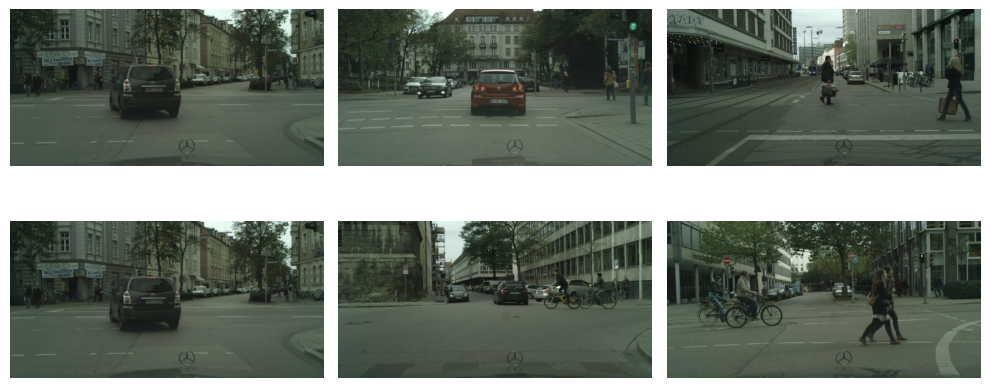

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(10, 5))
for ax, sample in zip(axes.flat, sample_paths_4):
    img = cv2.imread(str(sample))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.axis("off")

plt.tight_layout()
plt.show()

Random images from intersections with `degree = 3`

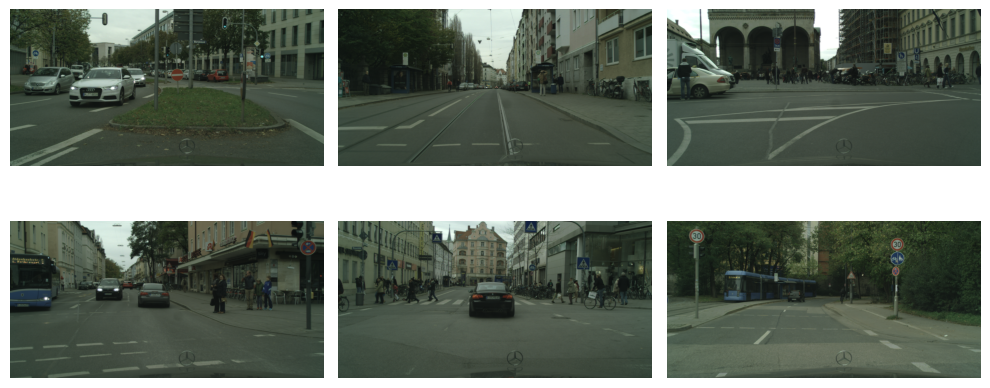

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(10, 5))
for ax, sample in zip(axes.flat, sample_paths_3):
    img = cv2.imread(str(sample))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.axis("off")

plt.tight_layout()
plt.show()